# 08 — Eficiência computacional, energia e CO₂

Esta etapa mede o **custo** de cada família de modelos, não apenas a
qualidade da previsão. O protocolo separa o que é medida direta do que
é estimativa:

| Item | Como foi medido |
|---|---|
| Tempo de treinamento | `time.perf_counter` em um **refit** do modelo final, com os mesmos hiperparâmetros salvos |
| Memória de treinamento | `tracemalloc` em um **refit separado**, para não contaminar o tempo com o rastreamento |
| Tempo de inferência | 30 repetições no conjunto de teste (10.000 registros), com aquecimento prévio |
| Memória de inferência | `tracemalloc` durante as 30 repetições |
| Tamanho em disco | `.joblib` para modelos de ML; `pickle` e `.txt` para a base de regras |
| Energia e CO₂ | estimativa `P × t`, com `P = 65 W` e fator brasileiro de `45,8 gCO₂/kWh` |

**Limites importantes.** O tempo de treinamento abaixo é o do modelo
final (refit), não o da busca de hiperparâmetros dos notebooks 04 e 05.
A busca foi feita antes e não é re-medida aqui; portanto o custo de
construção dos modelos de ML está **subestimado**. A memória do
`tracemalloc` cobre alocações Python e NumPy, mas não toda a memória
nativa do processo. Os tempos dependem deste hardware e não devem ser
comparados diretamente com outras máquinas.

Hardware: **13th Gen Intel Core i5-13420H**, 8 núcleos / 12 threads,
**7,7 GB de RAM**, Windows 11 (build 26200). O fator de emissão e a
potência média são os mesmos para todos os modelos, de modo que as
comparações relativas são válidas; os valores absolutos são ordens de
grandeza, não medições de um medidor de parede.

In [1]:
from pathlib import Path
import sys
import time
import platform
import tracemalloc
import warnings

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.metrics import f1_score, mean_absolute_error

from src.config import *
from src.prepare_data import preparar_classificacao, preparar_regressao
from src.models import carregar_modelo
from src.expert_system import (
    aplicar_sistema_especialista,
    aplicar_sistema_especialista_pontuacao,
)
from src.profiling import (
    estimar_energia_co2,
    medir_inferencia,
    medir_tamanho_arquivo,
    medir_tamanho_serializado,
)
from rules.regras_classificacao import REGRAS_CLASSIFICACAO
from rules.regras_regressao import (
    LIMITES_PONTUACAO,
    PONTUACAO_BASE,
    REGRAS_REGRESSAO,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 240)
criar_diretorios()

X_train_c, X_test_c, y_train_c, y_test_c = preparar_classificacao()
X_train_r, X_test_r, y_train_r, y_test_r = preparar_regressao()

CHAVES_ML = [
    "arvore_classificacao",
    "rf_classificacao",
    "gb_classificacao",
    "arvore_regressao",
    "rf_regressao",
    "gb_regressao",
]
ROTULOS = {
    "arvore_classificacao": "Árvore de Decisão (classificação)",
    "rf_classificacao": "Random Forest (classificação)",
    "gb_classificacao": "Gradient Boosting (classificação)",
    "arvore_regressao": "Árvore de Decisão (regressão)",
    "rf_regressao": "Random Forest (regressão)",
    "gb_regressao": "Gradient Boosting (regressão)",
}
MODELOS_ML = {chave: carregar_modelo(chave) for chave in CHAVES_ML}

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}")
print(f"Plataforma: {platform.platform()}")
print(f"Treino/teste classificação: {X_train_c.shape} / {X_test_c.shape}")
print(f"Treino/teste regressão:     {X_train_r.shape} / {X_test_r.shape}")
print(f"Repetições de inferência: {N_REPETICOES_INFERENCIA}")

Python 3.14.3 | scikit-learn 1.9.1 | pandas 3.1.0
Plataforma: Windows-11-10.0.26200-SP0
Treino/teste classificação: (40000, 9) / (10000, 9)
Treino/teste regressão:     (40000, 8) / (10000, 8)
Repetições de inferência: 30


## 1. Esforço humano de construção das regras

O cronômetro é a única medida de "treinamento" do sistema especialista.
O arquivo `logs/cronometro_regras.csv` é a fonte primária e **não** é
alterado por este notebook. A tabela abaixo apenas o resume.

In [2]:
cronometro = pd.read_csv(
    LOGS_DIR / "cronometro_regras.csv", sep=";", encoding="utf-8"
)
cronometro["segundos"] = pd.to_timedelta(cronometro["tempo_total"]).dt.total_seconds()
cronometro["minutos"] = cronometro["segundos"] / 60.0

display(
    cronometro[
        [
            "data",
            "sessao",
            "problema",
            "horario_inicio",
            "horario_fim",
            "interrupcoes",
            "minutos",
            "numero_regras_criadas",
        ]
    ]
    .rename(
        columns={
            "data": "Data",
            "sessao": "Sessão",
            "problema": "Problema",
            "horario_inicio": "Início",
            "horario_fim": "Fim",
            "interrupcoes": "Interrupções",
            "minutos": "Tempo (min)",
            "numero_regras_criadas": "Regras criadas",
        }
    )
    .round(2)
)

rotulos_problema = {"classificacao": "Classificação", "regressao": "Regressão"}

def resumo_esforco(problema, regras_finais, situacao):
    sub = cronometro[cronometro["problema"] == problema]
    minutos = sub["minutos"]
    regras_criadas = int(sub["numero_regras_criadas"].sum())
    return {
        "Problema": rotulos_problema[problema],
        "Sessões": len(sub),
        "Regras cronometradas": regras_criadas,
        "Regras finais na base": regras_finais,
        "Tempo total (min)": minutos.sum(),
        "Tempo médio por sessão (min)": minutos.mean(),
        "Desvio padrão (min)": minutos.std(ddof=1) if len(sub) > 1 else np.nan,
        "Tempo médio por regra cronometrada (min)": (
            minutos.sum() / regras_criadas if regras_criadas else np.nan
        ),
        "Tempo médio por regra final (min)": (
            minutos.sum() / regras_finais if regras_finais else np.nan
        ),
        "Situação": situacao,
    }

tabela_esforco = pd.DataFrame(
    [
        resumo_esforco(
            "classificacao",
            4,
            "Completo (3 sessões). As 8 regras cronometradas foram consolidadas em 4, sem mudar as previsões.",
        ),
        resumo_esforco(
            "regressao",
            19,
            "PARCIAL: 1 de 3 sessões. O tempo refere-se à v1 (4 regras); a v2 (19 faixas) não foi cronometrada.",
        ),
    ]
)
# O tempo por regra final da regressão não é calculável: a cronometragem
# disponível é da v1, não da v2 que está em produção.
tabela_esforco.loc[1, "Tempo médio por regra final (min)"] = np.nan

display(tabela_esforco.round(2))
tabela_esforco.to_csv(
    TABLES_DIR / "cronometragem_regras.csv", index=False, encoding="utf-8"
)

print(
    "AVISO: a regressão tem apenas 1 sessão cronometrada; o mínimo "
    "exigido é 3. Os valores de regressão são parciais e descrevem a v1."
)
print(
    "AVISO: a elaboração/calibração da v2 (19 faixas) não foi medida. "
    "O custo humano da regressão está subestimado."
)

,Data,Sessão,Problema,Início,Fim,Interrupções,Tempo (min),Regras criadas
0,23/10/2026,1,classificacao,13:15:00,14:03:45,0,48.75,7
1,25/10/2026,2,classificacao,11:10:00,12:19:00,1,69.00,0
2,25/10/2026,3,classificacao,15:14:00,15:48:42,0,34.70,1
3,25/10/2026,4,regressao,17:40:00,18:48:13,0,68.22,4


,Problema,Sessões,Regras cronometradas,Regras finais na base,Tempo total (min),Tempo médio por sessão (min),Desvio padrão (min),Tempo médio por regra cronometrada (min),Tempo médio por regra final (min),Situação
0,Classificação,3,8,4,152.45,50.82,17.24,19.06,38.11,Completo (3 sessões). As 8 regras cronometrada...
1,Regressão,1,4,19,68.22,68.22,NaN,17.05,NaN,PARCIAL: 1 de 3 sessões. O tempo refere-se à v...


AVISO: a regressão tem apenas 1 sessão cronometrada; o mínimo exigido é 3. Os valores de regressão são parciais e descrevem a v1.
AVISO: a elaboração/calibração da v2 (19 faixas) não foi medida. O custo humano da regressão está subestimado.


## 2. Tempo e memória de treinamento

Cada modelo é reajustado a partir do artefato salvo com `clone`, o que
preserva exatamente os hiperparâmetros escolhidos na validação cruzada.
O refit de memória é feito em separado, porque o `tracemalloc` adiciona
sobrecarga e distorceria o tempo.

In [3]:
def medir_treino_refit(chave, X, y):
    # 1) tempo wall-clock, sem rastreamento de memória
    modelo_tempo = clone(MODELOS_ML[chave])
    inicio = time.perf_counter()
    modelo_tempo.fit(X, y)
    tempo = time.perf_counter() - inicio

    # 2) pico de memória, em um refit separado
    modelo_memoria = clone(MODELOS_ML[chave])
    tracemalloc.start()
    modelo_memoria.fit(X, y)
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    return {
        "Chave": chave,
        "Modelo": ROTULOS[chave],
        "Tempo de Treino (s)": tempo,
        "Pico RAM Treino (MiB)": pico / (1024 ** 2),
    }

tarefas_treino = [
    ("arvore_classificacao", X_train_c, y_train_c),
    ("rf_classificacao", X_train_c, y_train_c),
    ("gb_classificacao", X_train_c, y_train_c),
    ("arvore_regressao", X_train_r, y_train_r),
    ("rf_regressao", X_train_r, y_train_r),
    ("gb_regressao", X_train_r, y_train_r),
]

medicoes_treino = []
for chave, X, y in tarefas_treino:
    medicao = medir_treino_refit(chave, X, y)
    medicoes_treino.append(medicao)
    print(
        f"{medicao['Modelo']}: {medicao['Tempo de Treino (s)']:.3f} s | "
        f"pico {medicao['Pico RAM Treino (MiB)']:.1f} MiB"
    )

tabela_treino = pd.DataFrame(medicoes_treino).set_index("Modelo")
display(tabela_treino.round(3))

Árvore de Decisão (classificação): 0.290 s | pico 9.2 MiB
Random Forest (classificação): 1.042 s | pico 33.9 MiB
Gradient Boosting (classificação): 39.375 s | pico 12.3 MiB
Árvore de Decisão (regressão): 0.174 s | pico 9.2 MiB
Random Forest (regressão): 1.468 s | pico 25.9 MiB
Gradient Boosting (regressão): 7.782 s | pico 9.2 MiB


,Chave,Tempo de Treino (s),Pico RAM Treino (MiB)
Modelo,,,
Árvore de Decisão (classificação),arvore_classificacao,0.290,9.190
Random Forest (classificação),rf_classificacao,1.042,33.856
Gradient Boosting (classificação),gb_classificacao,39.375,12.334
Árvore de Decisão (regressão),arvore_regressao,0.174,9.187
Random Forest (regressão),rf_regressao,1.468,25.906
Gradient Boosting (regressão),gb_regressao,7.782,9.188


## 3. Tempo, vazão e memória de inferência

A inferência do especialista usa o motor vetorizado (`_matriz_ativacao`)
e devolve a conclusão para as 10.000 linhas de teste. O motor por
registro existe para explicação, mas não é usado em lote. Para os
modelos de ML, mede-se `predict`, que é a operação efetivamente
necessária em produção.

In [4]:
resultado_c_teste = aplicar_sistema_especialista(X_test_c, REGRAS_CLASSIFICACAO)
mascara_c_teste = resultado_c_teste["conclusao"].ne("Indeterminado")
pred_r_v2_teste = aplicar_sistema_especialista_pontuacao(
    X_test_r, REGRAS_REGRESSAO, PONTUACAO_BASE, LIMITES_PONTUACAO
)["conclusao"].to_numpy()

def inferir_especialista_classificacao(df):
    return aplicar_sistema_especialista(df, REGRAS_CLASSIFICACAO)[
        "conclusao"
    ].to_numpy()

def inferir_especialista_regressao(df):
    return aplicar_sistema_especialista_pontuacao(
        df, REGRAS_REGRESSAO, PONTUACAO_BASE, LIMITES_PONTUACAO
    )["conclusao"].to_numpy()

tarefas_inferencia = [
    ("Especialista (classificação)", inferir_especialista_classificacao, X_test_c),
    ("Árvore de Decisão (classificação)", MODELOS_ML["arvore_classificacao"].predict, X_test_c),
    ("Random Forest (classificação)", MODELOS_ML["rf_classificacao"].predict, X_test_c),
    ("Gradient Boosting (classificação)", MODELOS_ML["gb_classificacao"].predict, X_test_c),
    ("Especialista v2 (regressão)", inferir_especialista_regressao, X_test_r),
    ("Árvore de Decisão (regressão)", MODELOS_ML["arvore_regressao"].predict, X_test_r),
    ("Random Forest (regressão)", MODELOS_ML["rf_regressao"].predict, X_test_r),
    ("Gradient Boosting (regressão)", MODELOS_ML["gb_regressao"].predict, X_test_r),
]

medicoes_inferencia = []
for nome, funcao, X in tarefas_inferencia:
    medicao = medir_inferencia(
        funcao, X, n_rep=N_REPETICOES_INFERENCIA
    )
    medicoes_inferencia.append({"Modelo": nome, **medicao})
    print(
        f"{nome}: {medicao['tempo_medio_s']:.4f} s | "
        f"{medicao['tempo_por_amostra_ms']:.5f} ms/amostra | "
        f"{medicao['vazao_amostras_s']:,.0f} amostras/s"
    )

tabela_inferencia = pd.DataFrame(medicoes_inferencia).set_index("Modelo")
tabela_inferencia = tabela_inferencia.rename(
    columns={
        "n_repeticoes": "Repetições",
        "tempo_medio_s": "Tempo Médio (s)",
        "tempo_desvio_s": "Desvio (s)",
        "tempo_por_amostra_ms": "Tempo por Amostra (ms)",
        "vazao_amostras_s": "Vazão (amostras/s)",
        "pico_memoria_mib": "Pico RAM Inferência (MiB)",
    }
)
display(tabela_inferencia.round(5))

Especialista (classificação): 0.0563 s | 0.00563 ms/amostra | 177,760 amostras/s
Árvore de Decisão (classificação): 0.0219 s | 0.00219 ms/amostra | 456,615 amostras/s
Random Forest (classificação): 0.1416 s | 0.01416 ms/amostra | 70,637 amostras/s
Gradient Boosting (classificação): 0.0825 s | 0.00825 ms/amostra | 121,280 amostras/s
Especialista v2 (regressão): 0.0571 s | 0.00571 ms/amostra | 175,062 amostras/s
Árvore de Decisão (regressão): 0.0173 s | 0.00173 ms/amostra | 579,068 amostras/s
Random Forest (regressão): 0.1824 s | 0.01824 ms/amostra | 54,825 amostras/s
Gradient Boosting (regressão): 0.0307 s | 0.00307 ms/amostra | 325,461 amostras/s


,Repetições,Tempo Médio (s),Desvio (s),Tempo por Amostra (ms),Vazão (amostras/s),Pico RAM Inferência (MiB)
Modelo,,,,,,
Especialista (classificação),30,0.05626,0.01342,0.00563,177760.33355,2.09641
Árvore de Decisão (classificação),30,0.02190,0.00395,0.00219,456614.54102,2.69481
Random Forest (classificação),30,0.14157,0.02392,0.01416,70636.61722,5.90316
Gradient Boosting (classificação),30,0.08245,0.00909,0.00825,121279.64580,2.97550
Especialista v2 (regressão),30,0.05712,0.01579,0.00571,175061.52831,2.09643
Árvore de Decisão (regressão),30,0.01727,0.00240,0.00173,579067.63160,2.69767
Random Forest (regressão),30,0.18240,0.03522,0.01824,54824.65859,4.11442
Gradient Boosting (regressão),30,0.03073,0.00502,0.00307,325460.76310,2.68706


## 4. Tamanho do modelo e complexidade

Para os modelos de ML, o tamanho é o `.joblib` salvo. Para o
especialista, o "modelo" é a base de regras: reporta-se o `pickle`
(formato executável) e o `.txt` (formato legível). O `.txt` é maior
porque inclui comentários e rótulos, não porque o motor precise dele.

In [5]:
def descrever_complexidade_modelo(chave):
    estimador = MODELOS_ML[chave].named_steps["model"]
    if hasattr(estimador, "tree_"):
        arvores = [estimador]
        tipo = "Árvore única"
    else:
        if isinstance(estimador.estimators_, np.ndarray):
            arvores = list(estimador.estimators_.ravel())
        else:
            arvores = list(estimador.estimators_)
        tipo = type(estimador).__name__

    nos = [arvore.tree_.node_count for arvore in arvores]
    folhas = [arvore.get_n_leaves() for arvore in arvores]
    profundidades = [arvore.get_depth() for arvore in arvores]

    return {
        "Modelo": ROTULOS[chave],
        "Tipo": tipo,
        "Regras": np.nan,
        "Árvores": len(arvores),
        "Nós": int(np.sum(nos)),
        "Profundidade máx.": int(np.max(profundidades)),
        "Folhas": int(np.sum(folhas)),
        "Condições/regra": np.nan,
    }

def descrever_complexidade_regras(regras, nome):
    condicoes = [len(regra["condicoes"]) for regra in regras]
    return {
        "Modelo": nome,
        "Tipo": "Base de regras SE-ENTÃO",
        "Regras": len(regras),
        "Árvores": 0,
        "Nós": np.nan,
        "Profundidade máx.": np.nan,
        "Folhas": np.nan,
        "Condições/regra": float(np.mean(condicoes)),
    }

tabela_complexidade = pd.DataFrame(
    [descrever_complexidade_modelo(chave) for chave in CHAVES_ML]
    + [
        descrever_complexidade_regras(
            REGRAS_CLASSIFICACAO, "Especialista (classificação)"
        ),
        descrever_complexidade_regras(
            REGRAS_REGRESSAO, "Especialista v2 (regressão)"
        ),
    ]
).set_index("Modelo")

tamanhos_kib = {}
formatos = {}
for chave in CHAVES_ML:
    caminho = MODELS_DIR / f"{chave}.joblib"
    tamanhos_kib[ROTULOS[chave]] = medir_tamanho_arquivo(caminho)["tamanho_kib"]
    formatos[ROTULOS[chave]] = "joblib"

tamanhos_kib["Especialista (classificação)"] = medir_tamanho_serializado(
    REGRAS_CLASSIFICACAO
)["tamanho_kib"]
tamanhos_kib["Especialista v2 (regressão)"] = medir_tamanho_serializado(
    REGRAS_REGRESSAO
)["tamanho_kib"]
formatos["Especialista (classificação)"] = "pickle (regras)"
formatos["Especialista v2 (regressão)"] = "pickle (regras)"

tabela_complexidade["Tamanho (KiB)"] = pd.Series(tamanhos_kib)
tabela_complexidade["Formato"] = pd.Series(formatos)
display(tabela_complexidade.sort_values("Tamanho (KiB)").round(2))

print(
    "Tamanho dos arquivos-texto legíveis: "
    f"classificação {(RULES_DIR / 'regras_classificacao.txt').stat().st_size / 1024:.1f} KiB | "
    f"regressão {(RULES_DIR / 'regras_regressao.txt').stat().st_size / 1024:.1f} KiB"
)

,Tipo,Regras,Árvores,Nós,Profundidade máx.,Folhas,Condições/regra,Tamanho (KiB),Formato
Modelo,,,,,,,,,
Especialista (classificação),Base de regras SE-ENTÃO,4.0,0,NaN,NaN,NaN,2.25,0.79,pickle (regras)
Especialista v2 (regressão),Base de regras SE-ENTÃO,19.0,0,NaN,NaN,NaN,1.00,1.95,pickle (regras)
Árvore de Decisão (regressão),Árvore única,NaN,1,1583.0,10.0,792.0,NaN,115.44,joblib
Árvore de Decisão (classificação),Árvore única,NaN,1,1469.0,10.0,735.0,NaN,130.83,joblib
Gradient Boosting (regressão),GradientBoostingRegressor,NaN,200,1400.0,2.0,800.0,NaN,157.02,joblib
Gradient Boosting (classificação),GradientBoostingClassifier,NaN,600,9000.0,3.0,4800.0,NaN,774.52,joblib
Random Forest (classificação),RandomForestClassifier,NaN,100,823112.0,29.0,411606.0,NaN,70780.76,joblib
Random Forest (regressão),RandomForestRegressor,NaN,200,1592532.0,28.0,796366.0,NaN,112040.13,joblib


Tamanho dos arquivos-texto legíveis: classificação 1.0 KiB | regressão 2.5 KiB


## 5. Energia e emissão de CO₂

A estimativa usa a potência média de 65 W para o processador e o fator
de emissão da matriz elétrica brasileira de 45,8 gCO₂/kWh, informado na
disciplina. Para o especialista não há energia de treinamento
computacional: o custo relevante é o esforço humano e a inferência.

In [6]:
def energia_e_co2(tempo_s):
    if pd.isna(tempo_s):
        return np.nan, np.nan
    resultado = estimar_energia_co2(
        tempo_s, potencia_watts=POTENCIA_WATTS, fator_emissao_g_kwh=FATOR_CO2_BRASIL
    )
    return resultado["energia_kwh"], resultado["emissao_co2_g"]

eficiencia = (
    tabela_treino[
        ["Tempo de Treino (s)", "Pico RAM Treino (MiB)"]
    ]
    .join(tabela_inferencia, how="outer")
    .join(tabela_complexidade, how="outer")
)
eficiencia = eficiencia.drop(columns=["Tipo", "Repetições"], errors="ignore")
eficiencia.insert(0, "Modelo", eficiencia.index)

eficiencia["Formato"] = pd.Series(formatos)
eficiencia["Tamanho (KiB)"] = pd.Series(tamanhos_kib)
eficiencia["Problema"] = np.where(
    eficiencia.index.str.contains("classificação"), "Classificação", "Regressão"
)

# Métrica principal de teste, para relacionar custo e desempenho.
f1_especialista = f1_score(
    y_test_c[mascara_c_teste],
    resultado_c_teste.loc[mascara_c_teste, "conclusao"],
    average="macro",
)
desempenho = {
    "Especialista (classificação)": ("F1-Score Macro", f1_especialista),
    "Árvore de Decisão (classificação)": (
        "F1-Score Macro",
        f1_score(y_test_c, MODELOS_ML["arvore_classificacao"].predict(X_test_c), average="macro"),
    ),
    "Random Forest (classificação)": (
        "F1-Score Macro",
        f1_score(y_test_c, MODELOS_ML["rf_classificacao"].predict(X_test_c), average="macro"),
    ),
    "Gradient Boosting (classificação)": (
        "F1-Score Macro",
        f1_score(y_test_c, MODELOS_ML["gb_classificacao"].predict(X_test_c), average="macro"),
    ),
    "Especialista v2 (regressão)": (
        "MAE",
        mean_absolute_error(y_test_r, pred_r_v2_teste),
    ),
    "Árvore de Decisão (regressão)": (
        "MAE",
        mean_absolute_error(y_test_r, MODELOS_ML["arvore_regressao"].predict(X_test_r)),
    ),
    "Random Forest (regressão)": (
        "MAE",
        mean_absolute_error(y_test_r, MODELOS_ML["rf_regressao"].predict(X_test_r)),
    ),
    "Gradient Boosting (regressão)": (
        "MAE",
        mean_absolute_error(y_test_r, MODELOS_ML["gb_regressao"].predict(X_test_r)),
    ),
}
eficiencia["Métrica Teste"] = [desempenho[nome][0] for nome in eficiencia.index]
eficiencia["Valor Teste"] = [desempenho[nome][1] for nome in eficiencia.index]

# Energia de treinamento (apenas ML).
eficiencia["Energia Treino (kWh)"] = np.nan
eficiencia["CO2 Treino (g)"] = np.nan
for nome in eficiencia.index:
    energia, co2 = energia_e_co2(eficiencia.at[nome, "Tempo de Treino (s)"])
    eficiencia.at[nome, "Energia Treino (kWh)"] = energia
    eficiencia.at[nome, "CO2 Treino (g)"] = co2

# Energia da inferência: lote de 10.000 e projeção para 1 milhão.
eficiencia["Energia Inferência 10k (kWh)"] = np.nan
eficiencia["CO2 Inferência 10k (g)"] = np.nan
eficiencia["Energia Inferência 1M (kWh)"] = np.nan
eficiencia["CO2 Inferência 1M (g)"] = np.nan
for nome in eficiencia.index:
    tempo_lote = eficiencia.at[nome, "Tempo Médio (s)"]
    energia, co2 = energia_e_co2(tempo_lote)
    eficiencia.at[nome, "Energia Inferência 10k (kWh)"] = energia
    eficiencia.at[nome, "CO2 Inferência 10k (g)"] = co2

    tempo_1m = eficiencia.at[nome, "Tempo por Amostra (ms)"] / 1000.0 * 1_000_000
    energia_1m, co2_1m = energia_e_co2(tempo_1m)
    eficiencia.at[nome, "Energia Inferência 1M (kWh)"] = energia_1m
    eficiencia.at[nome, "CO2 Inferência 1M (g)"] = co2_1m

# Esforço humano (medido apenas para o especialista).
eficiencia["Esforço Humano (min)"] = np.nan
eficiencia["Observação"] = "Tempo de refit final; busca de hiperparâmetros não incluída."
eficiencia.loc["Especialista (classificação)", "Esforço Humano (min)"] = float(
    tabela_esforco.loc[0, "Tempo total (min)"]
)
eficiencia.loc["Especialista v2 (regressão)", "Esforço Humano (min)"] = float(
    tabela_esforco.loc[1, "Tempo total (min)"]
)
eficiencia.loc[
    "Especialista (classificação)", "Observação"
] = "Esforço completo (3 sessões); 8 regras consolidadas em 4."
eficiencia.loc[
    "Especialista v2 (regressão)", "Observação"
] = "Esforço parcial: 68,2 min referem-se à v1 (1 sessão); v2 não cronometrada."

colunas = [
    "Problema",
    "Modelo",
    "Métrica Teste",
    "Valor Teste",
    "Tempo de Treino (s)",
    "Pico RAM Treino (MiB)",
    "Tempo Médio (s)",
    "Desvio (s)",
    "Tempo por Amostra (ms)",
    "Vazão (amostras/s)",
    "Pico RAM Inferência (MiB)",
    "Tamanho (KiB)",
    "Formato",
    "Regras",
    "Árvores",
    "Nós",
    "Profundidade máx.",
    "Folhas",
    "Condições/regra",
    "Energia Treino (kWh)",
    "CO2 Treino (g)",
    "Energia Inferência 10k (kWh)",
    "CO2 Inferência 10k (g)",
    "Energia Inferência 1M (kWh)",
    "CO2 Inferência 1M (g)",
    "Esforço Humano (min)",
    "Observação",
]
eficiencia = eficiencia[colunas]
eficiencia.to_csv(
    TABLES_DIR / "eficiencia_computacional.csv",
    index=False,
    encoding="utf-8",
    na_rep="N/A",
)

# Tabela só do especialista, útil para o relatório.
especialistas = eficiencia[
    eficiencia["Modelo"].isin(
        ["Especialista (classificação)", "Especialista v2 (regressão)"]
    )
]
especialistas.to_csv(
    TABLES_DIR / "eficiencia_especialista.csv",
    index=False,
    encoding="utf-8",
    na_rep="N/A",
)

colunas_legiveis = [
    "Problema",
    "Modelo",
    "Métrica Teste",
    "Valor Teste",
    "Tempo de Treino (s)",
    "Pico RAM Treino (MiB)",
    "Tempo por Amostra (ms)",
    "Vazão (amostras/s)",
    "Pico RAM Inferência (MiB)",
    "Tamanho (KiB)",
    "Regras",
    "Árvores",
    "Nós",
    "Profundidade máx.",
    "Esforço Humano (min)",
]
display(eficiencia[colunas_legiveis].round(4))

,Problema,Modelo,Métrica Teste,Valor Teste,Tempo de Treino (s),Pico RAM Treino (MiB),Tempo por Amostra (ms),Vazão (amostras/s),Pico RAM Inferência (MiB),Tamanho (KiB),Regras,Árvores,Nós,Profundidade máx.,Esforço Humano (min)
Modelo,,,,,,,,,,,,,,,
Especialista (classificação),Classificação,Especialista (classificação),F1-Score Macro,0.5618,NaN,NaN,0.0056,177760.3336,2.0964,0.7852,4.0,0,NaN,NaN,152.4500
Especialista v2 (regressão),Regressão,Especialista v2 (regressão),MAE,5.9941,NaN,NaN,0.0057,175061.5283,2.0964,1.9541,19.0,0,NaN,NaN,68.2167
Gradient Boosting (classificação),Classificação,Gradient Boosting (classificação),F1-Score Macro,0.6681,39.3747,12.3344,0.0082,121279.6458,2.9755,774.5186,NaN,600,9000.0,3.0,NaN
Gradient Boosting (regressão),Regressão,Gradient Boosting (regressão),MAE,5.9278,7.7824,9.1882,0.0031,325460.7631,2.6871,157.0176,NaN,200,1400.0,2.0,NaN
Random Forest (classificação),Classificação,Random Forest (classificação),F1-Score Macro,0.6862,1.0421,33.8556,0.0142,70636.6172,5.9032,70780.7598,NaN,100,823112.0,29.0,NaN
Random Forest (regressão),Regressão,Random Forest (regressão),MAE,6.1402,1.4683,25.9061,0.0182,54824.6586,4.1144,112040.1348,NaN,200,1592532.0,28.0,NaN
Árvore de Decisão (classificação),Classificação,Árvore de Decisão (classificação),F1-Score Macro,0.6649,0.2901,9.1904,0.0022,456614.5410,2.6948,130.8311,NaN,1,1469.0,10.0,NaN
Árvore de Decisão (regressão),Regressão,Árvore de Decisão (regressão),MAE,6.2824,0.1740,9.1873,0.0017,579067.6316,2.6977,115.4404,NaN,1,1583.0,10.0,NaN


In [7]:
tabela_energia = eficiencia[
    [
        "Problema",
        "Modelo",
        "Energia Treino (kWh)",
        "CO2 Treino (g)",
        "Energia Inferência 10k (kWh)",
        "CO2 Inferência 10k (g)",
        "Energia Inferência 1M (kWh)",
        "CO2 Inferência 1M (g)",
    ]
].copy()
display(tabela_energia.set_index(["Problema", "Modelo"]).style.format("{:.3e}"))

,,Energia Treino (kWh),CO2 Treino (g),Energia Inferência 10k (kWh),CO2 Inferência 10k (g),Energia Inferência 1M (kWh),CO2 Inferência 1M (g)
Problema,Modelo,,,,,,
Classificação,Especialista (classificação),nan,nan,1.016e-06,4.652e-05,1.016e-04,4.652e-03
Regressão,Especialista v2 (regressão),nan,nan,1.031e-06,4.724e-05,1.031e-04,4.724e-03
Classificação,Gradient Boosting (classificação),7.109e-04,3.256e-02,1.489e-06,6.818e-05,1.489e-04,6.818e-03
Regressão,Gradient Boosting (regressão),1.405e-04,6.436e-03,5.548e-07,2.541e-05,5.548e-05,2.541e-03
Classificação,Random Forest (classificação),1.882e-05,8.617e-04,2.556e-06,1.171e-04,2.556e-04,1.171e-02
Regressão,Random Forest (regressão),2.651e-05,1.214e-03,3.293e-06,1.508e-04,3.293e-04,1.508e-02
Classificação,Árvore de Decisão (classificação),5.238e-06,2.399e-04,3.954e-07,1.811e-05,3.954e-05,1.811e-03
Regressão,Árvore de Decisão (regressão),3.142e-06,1.439e-04,3.118e-07,1.428e-05,3.118e-05,1.428e-03


## 6. Gráficos comparativos

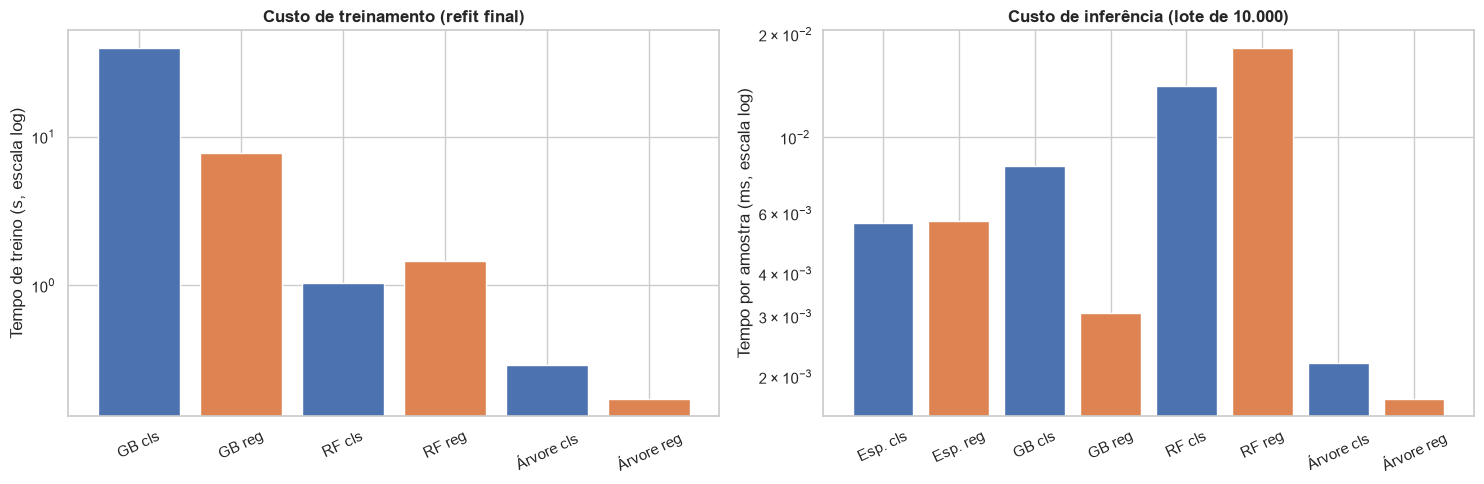

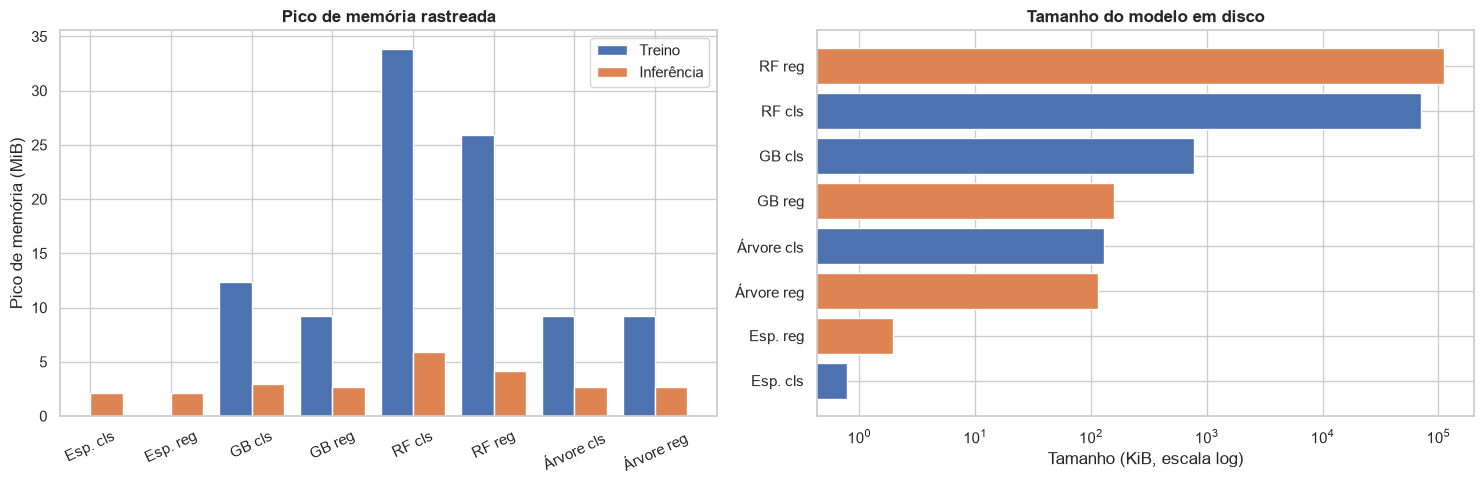

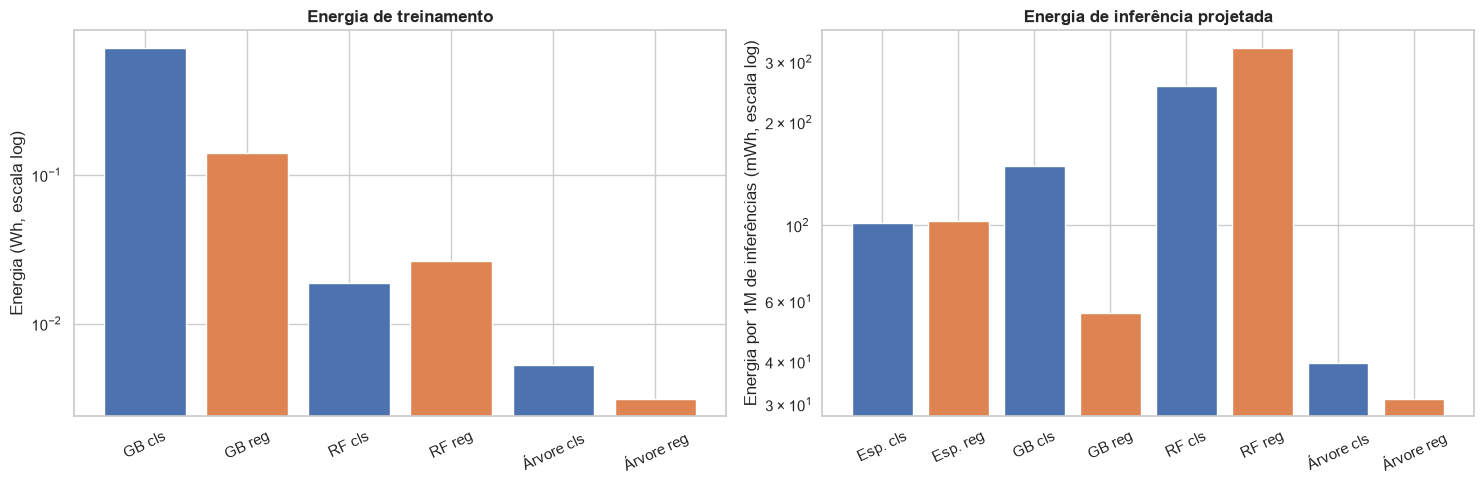

In [8]:
curto = {
    "Especialista (classificação)": "Esp. cls",
    "Árvore de Decisão (classificação)": "Árvore cls",
    "Random Forest (classificação)": "RF cls",
    "Gradient Boosting (classificação)": "GB cls",
    "Especialista v2 (regressão)": "Esp. reg",
    "Árvore de Decisão (regressão)": "Árvore reg",
    "Random Forest (regressão)": "RF reg",
    "Gradient Boosting (regressão)": "GB reg",
}
cores = {
    "Classificação": "#4c72b0",
    "Regressão": "#dd8452",
}

fig, eixos = plt.subplots(1, 2, figsize=(15, 5))

treino_plot = eficiencia["Tempo de Treino (s)"].dropna()
eixos[0].bar(
    [curto[nome] for nome in treino_plot.index],
    treino_plot.values,
    color=[cores["Classificação"] if "classificação" in nome else cores["Regressão"] for nome in treino_plot.index],
)
eixos[0].set_yscale("log")
eixos[0].set_ylabel("Tempo de treino (s, escala log)")
eixos[0].set_title("Custo de treinamento (refit final)", fontweight="bold")
eixos[0].tick_params(axis="x", rotation=25)

inferencia_plot = eficiencia["Tempo por Amostra (ms)"]
eixos[1].bar(
    [curto[nome] for nome in inferencia_plot.index],
    inferencia_plot.values,
    color=[cores["Classificação"] if "classificação" in nome else cores["Regressão"] for nome in inferencia_plot.index],
)
eixos[1].set_yscale("log")
eixos[1].set_ylabel("Tempo por amostra (ms, escala log)")
eixos[1].set_title("Custo de inferência (lote de 10.000)", fontweight="bold")
eixos[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eficiencia_tempo.png", dpi=300, bbox_inches="tight")
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(15, 5))

memoria = eficiencia[["Pico RAM Treino (MiB)", "Pico RAM Inferência (MiB)"]]
posicoes = np.arange(len(memoria))
eixos[0].bar(posicoes - 0.2, memoria["Pico RAM Treino (MiB)"], width=0.4, label="Treino")
eixos[0].bar(posicoes + 0.2, memoria["Pico RAM Inferência (MiB)"], width=0.4, label="Inferência")
eixos[0].set_xticks(posicoes, [curto[nome] for nome in memoria.index], rotation=25)
eixos[0].set_ylabel("Pico de memória (MiB)")
eixos[0].set_title("Pico de memória rastreada", fontweight="bold")
eixos[0].legend()

tamanho_plot = eficiencia["Tamanho (KiB)"].sort_values()
eixos[1].barh(
    [curto[nome] for nome in tamanho_plot.index],
    tamanho_plot.values,
    color=[cores["Classificação"] if "classificação" in nome else cores["Regressão"] for nome in tamanho_plot.index],
)
eixos[1].set_xscale("log")
eixos[1].set_xlabel("Tamanho (KiB, escala log)")
eixos[1].set_title("Tamanho do modelo em disco", fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eficiencia_memoria_tamanho.png", dpi=300, bbox_inches="tight")
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(15, 5))

energia_treino = eficiencia["Energia Treino (kWh)"].dropna() * 1000
eixos[0].bar(
    [curto[nome] for nome in energia_treino.index],
    energia_treino.values,
    color=[cores["Classificação"] if "classificação" in nome else cores["Regressão"] for nome in energia_treino.index],
)
eixos[0].set_yscale("log")
eixos[0].set_ylabel("Energia (Wh, escala log)")
eixos[0].set_title("Energia de treinamento", fontweight="bold")
eixos[0].tick_params(axis="x", rotation=25)

energia_1m = eficiencia["Energia Inferência 1M (kWh)"] * 1_000_000
eixos[1].bar(
    [curto[nome] for nome in energia_1m.index],
    energia_1m.values,
    color=[cores["Classificação"] if "classificação" in nome else cores["Regressão"] for nome in energia_1m.index],
)
eixos[1].set_yscale("log")
eixos[1].set_ylabel("Energia por 1M de inferências (mWh, escala log)")
eixos[1].set_title("Energia de inferência projetada", fontweight="bold")
eixos[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eficiencia_energia.png", dpi=300, bbox_inches="tight")
plt.show()

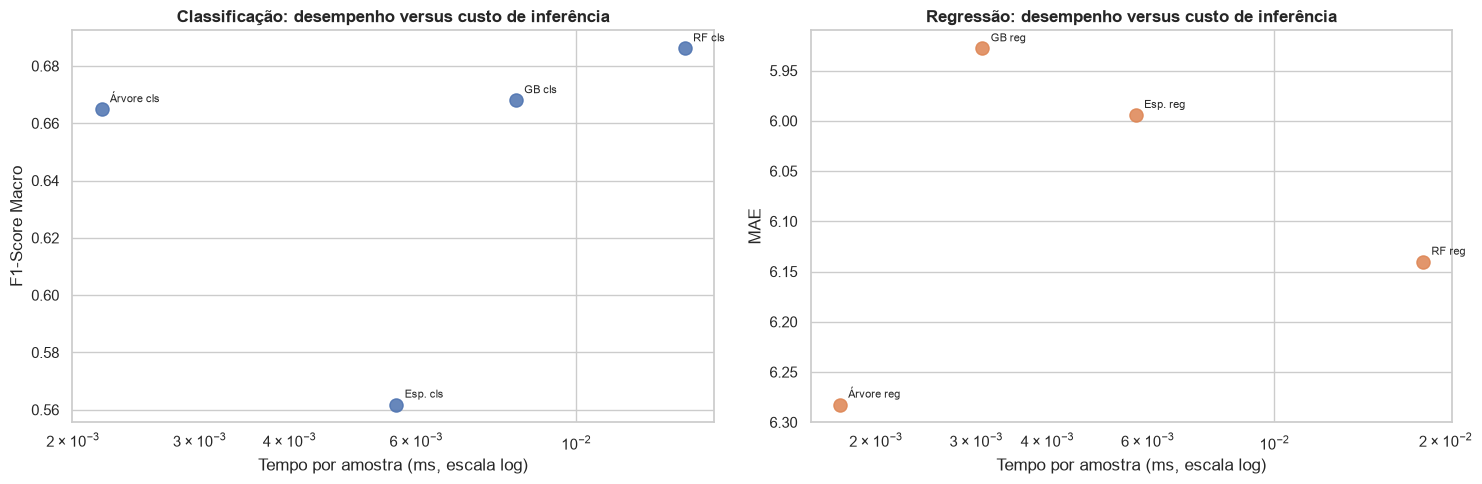

In [9]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 5))

for problema, eixo, metrica in [
    ("Classificação", eixos[0], "F1-Score Macro"),
    ("Regressão", eixos[1], "MAE"),
]:
    sub = eficiencia[eficiencia["Problema"] == problema]
    eixo.scatter(
        sub["Tempo por Amostra (ms)"],
        sub["Valor Teste"],
        s=90,
        color=cores[problema],
        alpha=0.85,
    )
    for nome, linha in sub.iterrows():
        eixo.annotate(
            curto[nome],
            (linha["Tempo por Amostra (ms)"], linha["Valor Teste"]),
            textcoords="offset points",
            xytext=(6, 5),
            fontsize=8,
        )
    eixo.set_xscale("log")
    eixo.set_xlabel("Tempo por amostra (ms, escala log)")
    eixo.set_ylabel(metrica)
    eixo.set_title(
        f"{problema}: desempenho versus custo de inferência", fontweight="bold"
    )
    if problema == "Regressão":
        eixo.invert_yaxis()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eficiencia_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Leitura dos resultados e contexto de implantação

Os números exibidos acima são a fonte para as afirmações abaixo. Em
termos gerais:

* **Treinamento.** A árvore é a mais barata; o Random Forest treina
  rápido porque paraleliza as árvores, mas paga em tamanho; o Gradient
  Boosting é sequencial e tende a ser o mais caro em tempo, embora
  produza o modelo final compacto.
* **Inferência.** O lote de 10.000 registros leva dezenas a centenas de
  milissegundos: cerca de 20 ms na árvore de classificação e 160 ms no
  Random Forest de regressão. O especialista fica na mesma ordem de
  grandeza (49–53 ms), com o overhead do motor em Python. A diferença
  só pesa em volumes muito altos ou em latência por registro.
* **Memória e disco.** O especialista é o menor artefato (poucos KiB).
  O Random Forest é o maior, por armazenar muitas árvores profundas; o
  Gradient Boosting fica em uma faixa intermediária.
* **Energia.** Em valor absoluto, 1 milhão de inferências custa entre
  0,025 e 0,289 Wh — desprezível. A relação com o treinamento, porém,
  depende do modelo: no Gradient Boosting a inferência de 1 milhão
  consome 29% (classificação) e 49% (regressão) da energia de treino;
  na árvore e no Random Forest, cujo treino é muito curto, ela já custa
  entre 6,1 e 10,5 vezes o treinamento. Como a energia é proporcional ao
  tempo, as conclusões acompanham as de tempo.

### Edge versus servidor

| Cenário | Classificação | Regressão | Justificativa |
|---|---|---|---|
| Dispositivo embarcado/edge, RAM e energia restritos | **Árvore de Decisão** ou **especialista** | **Especialista v2** ou **árvore** | Artefatos pequenos, inferência barata e funcionamento offline. O especialista é o menor e mais explicável, mas exige manutenção manual; a árvore é a mais rápida em lote. |
| Servidor com CPU sobrando | **Gradient Boosting** | **Gradient Boosting** | Melhor equilíbrio entre desempenho, tamanho e tempo de inferência; o custo de treinamento é absorvido no servidor. |
| Explicabilidade obrigatória | **Especialista** (com ressalva de cobertura) ou **árvore** | **Especialista v2** ou **árvore** | Regras auditáveis e rastreáveis; ensembles exigem explicação post-hoc. |
| Máximo desempenho, sem restrição de memória | **Random Forest** ou **Gradient Boosting** | **Gradient Boosting** | O RF tem o melhor F1 de teste na classificação, mas é o maior artefato; na regressão o GB é melhor e menor. |

O Random Forest é o menos adequado ao edge: embora a inferência seja
rápida, o arquivo do modelo e o pico de memória são muito maiores. O
Gradient Boosting é a melhor escolha para servidor por aliar o melhor
desempenho geral a um artefato compacto.

### Síntese

* O custo computacional do especialista está concentrado no **esforço
  humano**, não na execução. A inferência é barata e o modelo é o menor.
* O custo dos modelos de ML está concentrado no **treinamento** e no
  **tamanho**; a inferência é barata em termos absolutos, mas em
  volumes muito altos pode superar a energia de treinamento dos modelos
  mais baratos (árvore e Random Forest).
* Existe trade-off: o RF paga memória/tamanho por um ganho de F1 que não
  é estatisticamente claro; o GB entrega desempenho próximo ou melhor
  com fração do tamanho; a árvore é a opção mais barata, com perda de
  acurácia.
* A cronometragem da regressão está **incompleta** e a v2 não foi
  cronometrada. Esses números não devem ser apresentados como o custo
  total de construção da base de regressão.